<a href="https://www.kaggle.com/code/felmirra/gru-adapter-anmomal?scriptVersionId=311988450" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [2]:
import gc
import glob 
import numpy as np
import pandas as pd
import datetime as dt
import os

INPUT_DIR = "/kaggle/input/datasets/retailrocket/ecommerce-dataset"
WORK_DIR = "/kaggle/working/retailrocket_project"
STAGE01_DIR = os.path.join(WORK_DIR, "stage_01_retailrocket_preprocessing")

SOURCE_EVENTS = os.path.join(INPUT_DIR, "events.csv")
OUTPUT_DIR = STAGE01_DIR

os.makedirs(OUTPUT_DIR, exist_ok=True)
def build_retailrocket_gru4rec_tables(events_csv_path: str, output_dir: str):
    print("Чтение events.csv ...")
    raw_events = pd.read_csv(events_csv_path)
    print("Исходный размер:", raw_events.shape)
    print("Столбцы:", list(raw_events.columns))

    # Базовая подготовка
    log_df = raw_events.copy()
    log_df["user_id_tmp"] = log_df["visitorid"].values
    log_df["product_id_tmp"] = log_df["itemid"].values

    # Сортировка событий
    log_df = log_df.sort_values(
        ["user_id_tmp", "timestamp", "product_id_tmp"]
    ).reset_index(drop=True)

    # Формирование session_id:
    # новая сессия, если сменился пользователь
    # или если разрыв между соседними событиями > 1 часа
    next_session_flag = np.hstack([
        False,
        (
            (log_df["timestamp"].values[1:] - log_df["timestamp"].values[:-1]) > 3600 * 1000
        ) | (
            log_df["user_id_tmp"].values[1:] != log_df["user_id_tmp"].values[:-1]
        )
    ])
    log_df["session_id_tmp"] = np.cumsum(next_session_flag)

    # Оставляем только просмотры
    views_only = log_df.loc[
        log_df["event"] == "view",
        ["session_id_tmp", "product_id_tmp", "timestamp"]
    ].copy()
    views_only.columns = ["session_id", "item_id", "time"]

    print("\nПосле фильтрации event == 'view':")
    print("Размер:", views_only.shape)
    print("Сессий:", views_only["session_id"].nunique())
    print("Товаров:", views_only["item_id"].nunique())

    # Убираем подряд идущие дубли item внутри одной сессии
    consecutive_duplicate_mask = np.hstack([
        False,
        (
            (views_only["session_id"].values[1:] == views_only["session_id"].values[:-1]) &
            (views_only["item_id"].values[1:] == views_only["item_id"].values[:-1])
        )
    ])

    cleaned_views = views_only.loc[~consecutive_duplicate_mask].copy()

    print("\nПосле удаления подряд идущих дублей:")
    print("Размер:", cleaned_views.shape)
    print("Сессий:", cleaned_views["session_id"].nunique())
    print("Товаров:", cleaned_views["item_id"].nunique())

    # Итеративная очистка:
    # 1) удаляем сессии длины 1
    # 2) удаляем товары с поддержкой < 5
    previous_size = -1
    iteration_num = 0

    while len(cleaned_views) != previous_size:
        iteration_num += 1
        previous_size = len(cleaned_views)

        session_sizes = cleaned_views.groupby("session_id").size()
        valid_sessions = session_sizes[session_sizes > 1].index
        cleaned_views = cleaned_views[cleaned_views["session_id"].isin(valid_sessions)].copy()
        gc.collect()

        item_support = cleaned_views.groupby("item_id").size()
        frequent_items = item_support[item_support >= 5].index
        cleaned_views = cleaned_views[cleaned_views["item_id"].isin(frequent_items)].copy()
        gc.collect()

        print(f"\nИтерация очистки {iteration_num}:")
        print("Размер:", cleaned_views.shape)
        print("Сессий:", cleaned_views["session_id"].nunique())
        print("Товаров:", cleaned_views["item_id"].nunique())

    # Финальный полный датасет
    final_full = pd.DataFrame({
        "SessionId": cleaned_views["session_id"].values,
        "ItemId": cleaned_views["item_id"].values,
        "Time": cleaned_views["time"].values,
    })

    full_path = os.path.join(output_dir, "retailrocket_processed_view_full.tsv")
    final_full.to_csv(full_path, sep="\t", index=False)

    print("\nСохранён полный файл:")
    print(full_path)

    # Временной split как в оригинальном preprocessing
    tsplit_ms = 1442545200000
    one_day_ms = 86400 * 1000

    session_start_time = final_full.groupby("SessionId")["Time"].min()

    test_session_ids = session_start_time[session_start_time >= tsplit_ms - one_day_ms * 7].index
    test_df = final_full[final_full["SessionId"].isin(test_session_ids)].copy()
    train_full_df = final_full[final_full["Time"] < tsplit_ms - one_day_ms * 7].copy()

    # train_full: ещё раз гарантируем длину сессии > 1
    train_session_sizes = train_full_df.groupby("SessionId").size()
    valid_train_sessions = train_session_sizes[train_session_sizes > 1].index
    train_full_df = train_full_df[train_full_df["SessionId"].isin(valid_train_sessions)].copy()

    train_full_path = os.path.join(output_dir, "retailrocket_processed_view_train_full.tsv")
    test_path = os.path.join(output_dir, "retailrocket_processed_view_test.tsv")

    train_full_df.to_csv(train_full_path, sep="\t", index=False)
    test_df.to_csv(test_path, sep="\t", index=False)

    print("\nСохранены train/test:")
    print(train_full_path)
    print(test_path)

    # Дополнительный train/valid split внутри train
    train_inner_df = train_full_df[train_full_df["Time"] < tsplit_ms - one_day_ms * 14].copy()
    valid_session_ids = session_start_time[session_start_time >= tsplit_ms - one_day_ms * 14].index
    valid_df = train_full_df[train_full_df["SessionId"].isin(valid_session_ids)].copy()

    inner_train_sizes = train_inner_df.groupby("SessionId").size()
    valid_inner_train_sessions = inner_train_sizes[inner_train_sizes > 1].index
    train_inner_df = train_inner_df[train_inner_df["SessionId"].isin(valid_inner_train_sessions)].copy()

    train_tr_path = os.path.join(output_dir, "retailrocket_processed_view_train_tr.tsv")
    train_valid_path = os.path.join(output_dir, "retailrocket_processed_view_train_valid.tsv")

    train_inner_df.to_csv(train_tr_path, sep="\t", index=False)
    valid_df.to_csv(train_valid_path, sep="\t", index=False)

    print("\nСохранены train_tr/train_valid:")
    print(train_tr_path)
    print(train_valid_path)

    # Статистика по всем итоговым файлам
    summary_names = []
    summary_num_events = []
    summary_num_sessions = []
    summary_num_items = []
    summary_num_days = []
    summary_start = []
    summary_end = []
    summary_min_len = []
    summary_max_len = []
    summary_avg_len = []
    summary_avg_item_views = []
    summary_min_session_sec = []
    summary_max_session_sec = []

    for tsv_path in glob.glob(os.path.join(output_dir, "retailrocket_processed_view*.tsv")):
        part_df = pd.read_csv(tsv_path, sep="\t", dtype={"ItemId": "str"})

        summary_names.append(os.path.basename(tsv_path))
        summary_num_events.append(len(part_df))
        summary_num_sessions.append(part_df["SessionId"].nunique())
        summary_num_items.append(part_df["ItemId"].nunique())
        summary_num_days.append((part_df["Time"].max() - part_df["Time"].min()) / one_day_ms)

        summary_start.append(
            dt.datetime.utcfromtimestamp(part_df["Time"].min() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")
        )
        summary_end.append(
            dt.datetime.utcfromtimestamp(part_df["Time"].max() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")
        )

        per_session_len = part_df.groupby("SessionId").size()
        per_item_views = part_df.groupby("ItemId").size()
        per_session_duration = (
            part_df.groupby("SessionId")["Time"].max() - part_df.groupby("SessionId")["Time"].min()
        ) / 1000.0

        summary_min_len.append(per_session_len.min())
        summary_max_len.append(per_session_len.max())
        summary_avg_len.append(per_session_len.mean())
        summary_avg_item_views.append(per_item_views.mean())
        summary_min_session_sec.append(per_session_duration.min())
        summary_max_session_sec.append(per_session_duration.max())

    stats_df = pd.DataFrame({
        "Dataset": summary_names,
        "NumEvents": summary_num_events,
        "NumSessions": summary_num_sessions,
        "NumItems": summary_num_items,
        "NumDays": summary_num_days,
        "StartTime": summary_start,
        "EndTime": summary_end,
        "AvgItemViews": summary_avg_item_views,
        "MinSessionLength": summary_min_len,
        "MaxSessionLength": summary_max_len,
        "AvgSessionLength": summary_avg_len,
        "MinSessionTime_sec": summary_min_session_sec,
        "MaxSessionTime_sec": summary_max_session_sec,
    })

    stats_path = os.path.join(output_dir, "stats.tsv")
    stats_df.to_csv(stats_path, sep="\t", index=False, float_format="%.4f")

    print("\nИтоговая статистика:")
    display(stats_df)

    print("\nСохранён stats.tsv:")
    print(stats_path)

    return {
        "full": full_path,
        "train_full": train_full_path,
        "test": test_path,
        "train_tr": train_tr_path,
        "train_valid": train_valid_path,
        "stats": stats_path,
    }

saved_files = build_retailrocket_gru4rec_tables(
    events_csv_path=SOURCE_EVENTS,
    output_dir=OUTPUT_DIR
)

print("\nГотовые файлы:")
for key, value in saved_files.items():
    print(f"{key}: {value}")

print("\nФайлы в папке stage_01:")
for fname in sorted(os.listdir(STAGE01_DIR)):
    print(fname)

INPUT_DIR   = /kaggle/input/datasets/retailrocket/ecommerce-dataset
WORK_DIR    = /kaggle/working/retailrocket_project
STAGE01_DIR = /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing
SOURCE_EVENTS exists: True
Чтение events.csv ...
Исходный размер: (2756101, 5)
Столбцы: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

После фильтрации event == 'view':
Размер: (2664312, 3)
Сессий: 1721538
Товаров: 234838

После удаления подряд идущих дублей:
Размер: (2434084, 3)
Сессий: 1721538
Товаров: 234838

Итерация очистки 1:
Размер: (828902, 3)
Сессий: 242962
Товаров: 39826

Итерация очистки 2:
Размер: (784957, 3)
Сессий: 207891
Товаров: 37209

Итерация очистки 3:
Размер: (780685, 3)
Сессий: 204724
Товаров: 36903

Итерация очистки 4:
Размер: (780139, 3)
Сессий: 204353
Товаров: 36856

Итерация очистки 5:
Размер: (780044, 3)
Сессий: 204288
Товаров: 36848

Итерация очистки 6:
Размер: (780031, 3)
Сессий: 204277
Товаров: 36847

Итерация очистки 7:
Размер: (780031, 

/tmp/ipykernel_55/2910257430.py:186: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dt.datetime.utcfromtimestamp(part_df["Time"].min() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")
/tmp/ipykernel_55/2910257430.py:189: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dt.datetime.utcfromtimestamp(part_df["Time"].max() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")
/tmp/ipykernel_55/2910257430.py:186: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).


Итоговая статистика:


/tmp/ipykernel_55/2910257430.py:186: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dt.datetime.utcfromtimestamp(part_df["Time"].min() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")
/tmp/ipykernel_55/2910257430.py:189: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dt.datetime.utcfromtimestamp(part_df["Time"].max() / 1000).strftime("%Y-%m-%d %H:%M:%S.%f")


,Dataset,NumEvents,NumSessions,NumItems,NumDays,StartTime,EndTime,AvgItemViews,MinSessionLength,MaxSessionLength,AvgSessionLength,MinSessionTime_sec,MaxSessionTime_sec
0,retailrocket_processed_view_full.tsv,780031,204277,36847,137.998819,2015-05-03 03:00:40.988000,2015-09-18 02:58:58.914000,21.169457,2,260,3.818496,0.0,46604.003
1,retailrocket_processed_view_train_tr.tsv,716989,186821,36725,123.999511,2015-05-03 03:00:40.988000,2015-09-04 02:59:58.751000,19.523186,2,260,3.837839,0.0,46604.003
2,retailrocket_processed_view_train_full.tsv,750832,196234,36824,130.999083,2015-05-03 03:00:40.988000,2015-09-11 02:59:21.734000,20.389746,2,260,3.826207,0.0,46604.003
3,retailrocket_processed_view_train_valid.tsv,33812,9408,12668,6.999157,2015-09-04 03:00:34.595000,2015-09-11 02:59:21.734000,2.669087,2,147,3.593963,0.0,43014.633
4,retailrocket_processed_view_test.tsv,29148,8036,11249,6.998421,2015-09-11 03:01:15.381000,2015-09-18 02:58:58.914000,2.591164,2,200,3.627178,0.0,42992.512



Сохранён stats.tsv:
/kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/stats.tsv

Готовые файлы:
full: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_full.tsv
train_full: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_train_full.tsv
test: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_test.tsv
train_tr: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_train_tr.tsv
train_valid: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_train_valid.tsv
stats: /kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/stats.tsv

Файлы в папке stage_01:
retailrocket_processed_view_full.tsv
retailrocket_processed_view_test.tsv
retailrocket_processed_view_train_full.tsv
retailrocket_processed_view_train_

In [ ]:
# АНОМАЛИИ 2
import os
import gc
import json
import pickle
import numpy as np
import pandas as pd

from functools import lru_cache
from sklearn.ensemble import IsolationForest

# =========================================================
# PATHS
# =========================================================
INPUT_DIR = "/kaggle/input/datasets/retailrocket/ecommerce-dataset"
WORK_DIR = "/kaggle/working/retailrocket_project"
STAGE01_DIR = os.path.join(WORK_DIR, "stage_01_retailrocket_preprocessing")
OUT_DIR = os.path.join(WORK_DIR, "stage_02_anomaly_detection_apply_all")
os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(STAGE01_DIR, "retailrocket_processed_view_train_tr.tsv")
VALID_PATH = os.path.join(STAGE01_DIR, "retailrocket_processed_view_train_valid.tsv")
TEST_PATH  = os.path.join(STAGE01_DIR, "retailrocket_processed_view_test.tsv")

ITEM_PROP_1 = os.path.join(INPUT_DIR, "item_properties_part1.csv")
ITEM_PROP_2 = os.path.join(INPUT_DIR, "item_properties_part2.csv")
CATEGORY_TREE = os.path.join(INPUT_DIR, "category_tree.csv")

print("TRAIN_PATH   :", TRAIN_PATH, os.path.exists(TRAIN_PATH))
print("VALID_PATH   :", VALID_PATH, os.path.exists(VALID_PATH))
print("TEST_PATH    :", TEST_PATH, os.path.exists(TEST_PATH))
print("ITEM_PROP_1  :", ITEM_PROP_1, os.path.exists(ITEM_PROP_1))
print("ITEM_PROP_2  :", ITEM_PROP_2, os.path.exists(ITEM_PROP_2))
print("CATEGORY_TREE:", CATEGORY_TREE, os.path.exists(CATEGORY_TREE))
print("OUT_DIR      :", OUT_DIR)

# =========================================================
# CONFIG
# =========================================================
CFG = {
    "iforest_n_estimators": 200,
    "iforest_contamination": 0.02,
    "iforest_random_state": 42,

    # strong anomaly = rule AND iforest
    "strong_logic": "and",

    # если хочешь мягче:
    # "rule_min_flags": 3
    # если хочешь как раньше:
    "rule_min_flags": 2,
}

ISO_FEATURES = [
    "session_length",
    "unique_items",
    "repeat_ratio",
    "session_duration_sec",
    "mean_delta_sec",
    "median_delta_sec",
    "min_delta_sec",
    "events_per_minute",
    "unique_categories",
    "mean_category_depth",
    "cat_jump_count",
    "cat_change_ratio",
    "mean_tree_jump",
    "max_tree_jump",
]

# =========================================================
# HELPERS
# =========================================================
def read_split_tsv(path, split_name):
    df = pd.read_csv(path, sep="\t")
    print(f"\n[{split_name}] loaded:", df.shape)
    print(f"[{split_name}] columns:", list(df.columns))

    required_cols = {"SessionId", "ItemId", "Time"}
    if not required_cols.issubset(df.columns):
        raise ValueError(f"{split_name}: expected columns {required_cols}, got {list(df.columns)}")

    df = df[["SessionId", "ItemId", "Time"]].copy()
    df["SessionId"] = pd.to_numeric(df["SessionId"], errors="coerce")
    df["ItemId"] = pd.to_numeric(df["ItemId"], errors="coerce")
    df["Time"] = pd.to_numeric(df["Time"], errors="coerce")

    df = df.dropna().copy()
    df["SessionId"] = df["SessionId"].astype(np.int64)
    df["ItemId"] = df["ItemId"].astype(np.int64)
    df["Time"] = df["Time"].astype(np.int64)

    df = df.sort_values(["SessionId", "Time", "ItemId"]).reset_index(drop=True)

    print(f"[{split_name}] after cleanup:", df.shape)
    print(f"[{split_name}] unique sessions:", df['SessionId'].nunique())
    print(f"[{split_name}] unique items   :", df['ItemId'].nunique())

    return df


def load_item_category_mapping():
    item_prop1 = pd.read_csv(ITEM_PROP_1)
    item_prop2 = pd.read_csv(ITEM_PROP_2)
    item_props = pd.concat([item_prop1, item_prop2], ignore_index=True)

    print("\nitem_properties total:", item_props.shape)

    cat_props = item_props[item_props["property"] == "categoryid"].copy()
    cat_props["itemid"] = pd.to_numeric(cat_props["itemid"], errors="coerce")
    cat_props["timestamp"] = pd.to_numeric(cat_props["timestamp"], errors="coerce")
    cat_props["categoryid"] = pd.to_numeric(cat_props["value"], errors="coerce")

    cat_props = cat_props.dropna(subset=["itemid", "timestamp", "categoryid"]).copy()
    cat_props["itemid"] = cat_props["itemid"].astype(np.int64)
    cat_props["timestamp"] = cat_props["timestamp"].astype(np.int64)
    cat_props["categoryid"] = cat_props["categoryid"].astype(np.int64)

    # последнее известное categoryid для item
    cat_props = cat_props.sort_values(["itemid", "timestamp"])
    item_to_category = (
        cat_props.groupby("itemid", as_index=False)
        .tail(1)[["itemid", "categoryid"]]
        .drop_duplicates("itemid")
    )

    print("items with category mapping:", len(item_to_category))
    return item_to_category


def load_category_tree():
    cat_tree = pd.read_csv(CATEGORY_TREE)
    cat_tree["categoryid"] = pd.to_numeric(cat_tree["categoryid"], errors="coerce")
    cat_tree["parentid"] = pd.to_numeric(cat_tree["parentid"], errors="coerce")
    cat_tree = cat_tree.dropna(subset=["categoryid"]).copy()
    cat_tree["categoryid"] = cat_tree["categoryid"].astype(np.int64)

    parent_map = {}
    for _, row in cat_tree.iterrows():
        cid = int(row["categoryid"])
        pid = row["parentid"]
        parent_map[cid] = None if pd.isna(pid) else int(pid)

    return parent_map


def build_ancestors_and_depths(parent_map):
    ancestors = {}
    depths = {}

    for cid in parent_map.keys():
        path = []
        visited = set()
        cur = cid

        while cur is not None and cur in parent_map and cur not in visited:
            visited.add(cur)
            path.append(cur)
            cur = parent_map[cur]

        ancestors[cid] = path
        depths[cid] = len(path) - 1

    return ancestors, depths


# глобально заполним позже
ancestors_map = None
depth_map = None

@lru_cache(maxsize=None)
def category_tree_distance(c1, c2):
    if c1 == c2:
        return 0.0
    if c1 not in ancestors_map or c2 not in ancestors_map:
        return np.nan

    anc1 = ancestors_map[c1]
    anc2 = ancestors_map[c2]
    set2 = set(anc2)

    lca = None
    for node in anc1:
        if node in set2:
            lca = node
            break

    if lca is None:
        return np.nan

    d1 = depth_map[c1]
    d2 = depth_map[c2]
    dlca = depth_map[lca]
    return float((d1 - dlca) + (d2 - dlca))


def build_session_features(df, item_to_category, split_name="unknown"):
    work = df.copy()

    # attach category
    work = work.merge(
        item_to_category.rename(columns={"itemid": "ItemId", "categoryid": "CategoryId"}),
        how="left",
        on="ItemId"
    )
    work["CategoryDepth"] = work["CategoryId"].map(depth_map)

    print(f"\n[{split_name}] after category merge:")
    print("shape            :", work.shape)
    print("category coverage:", round(work["CategoryId"].notna().mean(), 6))

    # -------------------------
    # base session features
    # -------------------------
    session_length = work.groupby("SessionId").size().rename("session_length")
    unique_items = work.groupby("SessionId")["ItemId"].nunique().rename("unique_items")

    time_min = work.groupby("SessionId")["Time"].min().rename("time_min")
    time_max = work.groupby("SessionId")["Time"].max().rename("time_max")
    session_duration_sec = ((time_max - time_min) / 1000.0).rename("session_duration_sec")

    unique_categories = work.groupby("SessionId")["CategoryId"].nunique().rename("unique_categories")
    mean_category_depth = work.groupby("SessionId")["CategoryDepth"].mean().rename("mean_category_depth")

    sf = pd.concat(
        [
            session_length,
            unique_items,
            session_duration_sec,
            unique_categories,
            mean_category_depth,
        ],
        axis=1
    ).reset_index()

    sf["repeat_ratio"] = 1.0 - (
        sf["unique_items"] / sf["session_length"].clip(lower=1)
    )

    sf["events_per_minute"] = (
        sf["session_length"] /
        (sf["session_duration_sec"] / 60.0).clip(lower=1e-6)
    )

    # -------------------------
    # delta features
    # -------------------------
    work["PrevTime"] = work.groupby("SessionId")["Time"].shift(1)
    work["delta_sec"] = (work["Time"] - work["PrevTime"]) / 1000.0

    delta_aggs = work.groupby("SessionId")["delta_sec"].agg(
        mean_delta_sec="mean",
        median_delta_sec="median",
        min_delta_sec="min"
    ).reset_index()

    sf = sf.merge(delta_aggs, on="SessionId", how="left")

    # -------------------------
    # category transitions
    # -------------------------
    work["PrevCategoryId"] = work.groupby("SessionId")["CategoryId"].shift(1)

    pair_df = work[
        work["PrevCategoryId"].notna() &
        work["CategoryId"].notna()
    ].copy()

    if len(pair_df) > 0:
        pair_df["PrevCategoryId"] = pair_df["PrevCategoryId"].astype(np.int64)
        pair_df["CategoryId"] = pair_df["CategoryId"].astype(np.int64)

        pair_df["cat_changed"] = (pair_df["PrevCategoryId"] != pair_df["CategoryId"]).astype(np.int8)
        pair_df["tree_jump"] = [
            category_tree_distance(int(a), int(b))
            for a, b in zip(pair_df["PrevCategoryId"].values, pair_df["CategoryId"].values)
        ]

        cat_pair_count = pair_df.groupby("SessionId").size().rename("valid_cat_pairs")
        cat_jump_count = pair_df.groupby("SessionId")["cat_changed"].sum().rename("cat_jump_count")
        cat_change_ratio = pair_df.groupby("SessionId")["cat_changed"].mean().rename("cat_change_ratio")
        mean_tree_jump = pair_df.groupby("SessionId")["tree_jump"].mean().rename("mean_tree_jump")
        max_tree_jump = pair_df.groupby("SessionId")["tree_jump"].max().rename("max_tree_jump")

        cat_features = pd.concat(
            [
                cat_pair_count,
                cat_jump_count,
                cat_change_ratio,
                mean_tree_jump,
                max_tree_jump,
            ],
            axis=1
        ).reset_index()

        sf = sf.merge(cat_features, on="SessionId", how="left")
    else:
        sf["valid_cat_pairs"] = np.nan
        sf["cat_jump_count"] = np.nan
        sf["cat_change_ratio"] = np.nan
        sf["mean_tree_jump"] = np.nan
        sf["max_tree_jump"] = np.nan

    print(f"[{split_name}] session_features shape:", sf.shape)
    return sf


def compute_train_fill_medians(sf_train):
    X_train = sf_train[ISO_FEATURES].copy()
    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    medians = X_train.median(numeric_only=True)
    return medians


def apply_fill_rules(sf, train_medians):
    out = sf.copy()

    out = out.replace([np.inf, -np.inf], np.nan)

    # сначала специальные fill, как у тебя было
    fill_with_zero = [
        "unique_categories",
        "valid_cat_pairs",
        "cat_jump_count",
    ]
    for col in fill_with_zero:
        if col in out.columns:
            out[col] = out[col].fillna(0)

    # потом всё остальное train-median
    for col in ISO_FEATURES:
        if col in out.columns:
            fill_value = train_medians[col] if col in train_medians.index else 0.0
            out[col] = out[col].fillna(fill_value)

    return out


def fit_rule_thresholds(sf_train):
    thresholds = {
        "p99_session_length": float(sf_train["session_length"].quantile(0.99)),
        "p99_unique_items": float(sf_train["unique_items"].quantile(0.99)),
        "p99_events_per_minute": float(sf_train["events_per_minute"].quantile(0.99)),
        "p01_median_delta": float(sf_train["median_delta_sec"].quantile(0.01)),
        "p99_unique_categories": float(sf_train["unique_categories"].quantile(0.99)),
        "p99_cat_change_ratio": float(sf_train["cat_change_ratio"].quantile(0.99)),
        "p99_mean_tree_jump": float(sf_train["mean_tree_jump"].quantile(0.99)),
        "p99_max_tree_jump": float(sf_train["max_tree_jump"].quantile(0.99)),
    }
    return thresholds


def apply_rule_detector(sf, thresholds, rule_min_flags=2):
    out = sf.copy()

    out["flag_long_session"] = (out["session_length"] > thresholds["p99_session_length"]).astype(int)
    out["flag_many_items"] = (out["unique_items"] > thresholds["p99_unique_items"]).astype(int)
    out["flag_fast_behavior"] = (out["events_per_minute"] > thresholds["p99_events_per_minute"]).astype(int)
    out["flag_tiny_gaps"] = (out["median_delta_sec"] < thresholds["p01_median_delta"]).astype(int)
    out["flag_many_categories"] = (out["unique_categories"] > thresholds["p99_unique_categories"]).astype(int)
    out["flag_category_chaos"] = (out["cat_change_ratio"] > thresholds["p99_cat_change_ratio"]).astype(int)
    out["flag_big_tree_jumps"] = (out["mean_tree_jump"] > thresholds["p99_mean_tree_jump"]).astype(int)
    out["flag_extreme_tree_jump"] = (out["max_tree_jump"] > thresholds["p99_max_tree_jump"]).astype(int)

    rule_cols = [
        "flag_long_session",
        "flag_many_items",
        "flag_fast_behavior",
        "flag_tiny_gaps",
        "flag_many_categories",
        "flag_category_chaos",
        "flag_big_tree_jumps",
        "flag_extreme_tree_jump",
    ]

    out["rule_score"] = out[rule_cols].sum(axis=1)
    out["rule_anomaly"] = (out["rule_score"] >= rule_min_flags).astype(int)

    return out


def fit_iforest(sf_train_filled):
    X_train = sf_train_filled[ISO_FEATURES].copy()

    iso = IsolationForest(
        n_estimators=CFG["iforest_n_estimators"],
        contamination=CFG["iforest_contamination"],
        random_state=CFG["iforest_random_state"],
        n_jobs=-1,
    )
    iso.fit(X_train)
    return iso


def apply_iforest(sf_filled, iso):
    out = sf_filled.copy()
    X = out[ISO_FEATURES].copy()

    out["iforest_pred"] = iso.predict(X)              # 1 normal, -1 anomaly
    out["iforest_anomaly"] = (out["iforest_pred"] == -1).astype(int)

    # score_samples: чем меньше, тем более аномально
    out["iforest_score_samples"] = iso.score_samples(X)
    out["iforest_decision_function"] = iso.decision_function(X)

    return out


def combine_detectors(sf, strong_logic="and"):
    out = sf.copy()

    if strong_logic == "and":
        out["strong_anomaly"] = (
            (out["rule_anomaly"] == 1) &
            (out["iforest_anomaly"] == 1)
        ).astype(int)
    elif strong_logic == "or":
        out["strong_anomaly"] = (
            (out["rule_anomaly"] == 1) |
            (out["iforest_anomaly"] == 1)
        ).astype(int)
    else:
        raise ValueError("strong_logic must be 'and' or 'or'")

    return out


def save_split_outputs(split_name, raw_df, sf_final):
    split_stub = f"retailrocket_processed_view_{split_name}"

    features_path = os.path.join(OUT_DIR, f"{split_stub}_session_features.csv")
    anomaly_ids_path = os.path.join(OUT_DIR, f"{split_stub}_strong_anomalous_session_ids.csv")
    cleaned_path = os.path.join(OUT_DIR, f"{split_stub}_cleaned.tsv")
    summary_path = os.path.join(OUT_DIR, f"{split_stub}_summary.csv")

    sf_final.to_csv(features_path, index=False)

    sf_final.loc[sf_final["strong_anomaly"] == 1, ["SessionId"]].to_csv(anomaly_ids_path, index=False)

    strong_sessions = set(sf_final.loc[sf_final["strong_anomaly"] == 1, "SessionId"].tolist())
    cleaned_df = raw_df[~raw_df["SessionId"].isin(strong_sessions)][["SessionId", "ItemId", "Time"]].copy()

    cleaned_df.to_csv(cleaned_path, sep="\t", index=False)

    summary_df = pd.DataFrame([{
        "split": split_name,
        "input_rows": len(raw_df),
        "input_sessions": raw_df["SessionId"].nunique(),
        "input_items": raw_df["ItemId"].nunique(),

        "rule_anomalies": int(sf_final["rule_anomaly"].sum()),
        "iforest_anomalies": int(sf_final["iforest_anomaly"].sum()),
        "strong_anomalies": int(sf_final["strong_anomaly"].sum()),

        "cleaned_rows": len(cleaned_df),
        "cleaned_sessions": cleaned_df["SessionId"].nunique(),
        "cleaned_items": cleaned_df["ItemId"].nunique(),
    }])
    summary_df.to_csv(summary_path, index=False)

    print(f"\n[{split_name}] saved:")
    print(features_path)
    print(anomaly_ids_path)
    print(cleaned_path)
    print(summary_path)

    return {
        "features_path": features_path,
        "anomaly_ids_path": anomaly_ids_path,
        "cleaned_path": cleaned_path,
        "summary_path": summary_path,
        "summary_df": summary_df,
    }


def process_one_split(raw_df, split_name, item_to_category, train_thresholds, train_medians, iso_model):
    sf = build_session_features(raw_df, item_to_category, split_name=split_name)
    sf = apply_fill_rules(sf, train_medians)
    sf = apply_rule_detector(sf, train_thresholds, rule_min_flags=CFG["rule_min_flags"])
    sf = apply_iforest(sf, iso_model)
    sf = combine_detectors(sf, strong_logic=CFG["strong_logic"])
    return sf


# =========================================================
# 1. LOAD REFERENCE TABLES
# =========================================================
item_to_category = load_item_category_mapping()

parent_map = load_category_tree()
ancestors_map, depth_map = build_ancestors_and_depths(parent_map)

print("\ncategory tree loaded")
print("num categories in tree:", len(parent_map))

# =========================================================
# 2. LOAD SPLITS
# =========================================================
train_df = read_split_tsv(TRAIN_PATH, "train_tr")
valid_df = read_split_tsv(VALID_PATH, "train_valid")
test_df  = read_split_tsv(TEST_PATH,  "test")

# =========================================================
# 3. FIT ONLY ON TRAIN
# =========================================================
print("\n================ FIT ON TRAIN_TR ONLY ================")

sf_train_raw = build_session_features(train_df, item_to_category, split_name="train_tr_fit")

# train medians
train_medians = compute_train_fill_medians(sf_train_raw)

# fill train using train medians
sf_train_filled = apply_fill_rules(sf_train_raw, train_medians)

# rule thresholds from TRAIN ONLY
train_thresholds = fit_rule_thresholds(sf_train_filled)

print("\nTrain thresholds:")
for k, v in train_thresholds.items():
    print(f"{k}: {v}")

# fit iforest on TRAIN ONLY
iso_model = fit_iforest(sf_train_filled)

# save fitted artifacts
thresholds_path = os.path.join(OUT_DIR, "train_rule_thresholds.json")
medians_path = os.path.join(OUT_DIR, "train_feature_medians.json")
iforest_path = os.path.join(OUT_DIR, "train_iforest.pkl")
config_path = os.path.join(OUT_DIR, "anomaly_config.json")

with open(thresholds_path, "w", encoding="utf-8") as f:
    json.dump(train_thresholds, f, ensure_ascii=False, indent=2)

with open(medians_path, "w", encoding="utf-8") as f:
    json.dump({k: float(v) for k, v in train_medians.to_dict().items()}, f, ensure_ascii=False, indent=2)

with open(iforest_path, "wb") as f:
    pickle.dump(iso_model, f)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(CFG, f, ensure_ascii=False, indent=2)

print("\nSaved fitted artifacts:")
print(thresholds_path)
print(medians_path)
print(iforest_path)
print(config_path)

# =========================================================
# 4. APPLY SAME RULES TO TRAIN / VALID / TEST
# =========================================================
print("\n================ APPLY TO ALL SPLITS ================")

sf_train_final = process_one_split(
    raw_df=train_df,
    split_name="train_tr",
    item_to_category=item_to_category,
    train_thresholds=train_thresholds,
    train_medians=train_medians,
    iso_model=iso_model,
)

sf_valid_final = process_one_split(
    raw_df=valid_df,
    split_name="train_valid",
    item_to_category=item_to_category,
    train_thresholds=train_thresholds,
    train_medians=train_medians,
    iso_model=iso_model,
)

sf_test_final = process_one_split(
    raw_df=test_df,
    split_name="test",
    item_to_category=item_to_category,
    train_thresholds=train_thresholds,
    train_medians=train_medians,
    iso_model=iso_model,
)

# =========================================================
# 5. SAVE CLEANED SPLITS
# =========================================================
train_out = save_split_outputs("train_tr", train_df, sf_train_final)
valid_out = save_split_outputs("train_valid", valid_df, sf_valid_final)
test_out  = save_split_outputs("test", test_df, sf_test_final)

# =========================================================
# 6. GLOBAL SUMMARY
# =========================================================
global_summary = pd.concat(
    [
        train_out["summary_df"],
        valid_out["summary_df"],
        test_out["summary_df"],
    ],
    ignore_index=True
)

global_summary_path = os.path.join(OUT_DIR, "global_anomaly_summary.csv")
global_summary.to_csv(global_summary_path, index=False)

print("\n================ GLOBAL SUMMARY ================")
print(global_summary)
print("\nSaved:", global_summary_path)

print("\n================ READY FILES FOR RECOMMENDER ================")
print("TRAIN CLEANED:", train_out["cleaned_path"])
print("VALID CLEANED:", valid_out["cleaned_path"])
print("TEST  CLEANED:", test_out["cleaned_path"])

gc.collect()
print("\nDone.")

In [ ]:
# parallel session streams + GRU + sampled negatives + BPR-max

import os
import gc
import math
import json
import random
import numpy as np
import pandas as pd
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adagrad
'''
# -----------------------------
# 0. PATHS
# -----------------------------
WORK_DIR = "/kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing"

TRAIN_PATH = os.path.join(WORK_DIR, "retailrocket_processed_view_train_tr.tsv")
VALID_PATH = os.path.join(WORK_DIR, "retailrocket_processed_view_train_valid.tsv")
TEST_PATH  = os.path.join(WORK_DIR, "retailrocket_processed_view_test.tsv")

OUTPUT_DIR = "/kaggle/working/retailrocket_project/stage_02_session_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TRAIN_PATH:", TRAIN_PATH, os.path.exists(TRAIN_PATH))
print("VALID_PATH:", VALID_PATH, os.path.exists(VALID_PATH))
print("TEST_PATH :", TEST_PATH, os.path.exists(TEST_PATH))
print("OUTPUT_DIR:", OUTPUT_DIR)
'''
# -----------------------------
# 0. PATHS АНОМАЛИИ
# -----------------------------
ANOMALY_DIR = "/kaggle/working/retailrocket_project/stage_02_anomaly_detection_apply_all"

TRAIN_PATH = os.path.join(
    ANOMALY_DIR,
    "retailrocket_processed_view_train_tr_cleaned.tsv"
)
VALID_PATH = os.path.join(
    ANOMALY_DIR,
    "retailrocket_processed_view_train_valid_cleaned.tsv"
)
TEST_PATH  = os.path.join(
    ANOMALY_DIR,
    "retailrocket_processed_view_test_cleaned.tsv"
)

OUTPUT_DIR = "/kaggle/working/retailrocket_project/stage_03_session_model_after_anomaly_apply_all"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TRAIN_PATH:", TRAIN_PATH, os.path.exists(TRAIN_PATH))
print("VALID_PATH:", VALID_PATH, os.path.exists(VALID_PATH))
print("TEST_PATH :", TEST_PATH, os.path.exists(TEST_PATH))
print("OUTPUT_DIR:", OUTPUT_DIR)


# -----------------------------
# 1. REPRODUCIBILITY
# -----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

# -----------------------------
# 2. CONFIG
# -----------------------------
CFG = {
    "session_col_candidates": ["SessionId", "session_id", "session"],
    "item_col_candidates":    ["ItemId", "item_id", "item"],
    "time_col_candidates":    ["Time", "timestamp", "time", "event_ts"],

    "hidden_size": 224,
    "embedding_dim": 224,
    "dropout_embed": 0.5,
    "dropout_hidden": 0.05,

    "batch_size": 80,
    "epochs": 20,
    "learning_rate": 0.05,
    "momentum_like": 0.0,

    "neg_samples": 2048,
    "sample_alpha": 0.4,
    "bpr_reg": 1.95,
    "elu_alpha": 0.5,

    "eval_k": [1, 5, 10, 15, 20],
    "max_eval_batches": None,
    "save_name": "session_next_net_after_anomaly.pt",
}

# -----------------------------
# 3. HELPERS
# -----------------------------
def detect_column(df, candidates, role_name):
    for c in candidates:
        if c in df.columns:
            return c
    raise ValueError(f"Не найден столбец для {role_name}. Есть столбцы: {list(df.columns)}")

def read_tsv_any(path):
    df = pd.read_csv(path, sep="\t")
    print(f"\nЗагружен файл: {os.path.basename(path)}")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    return df

def standardize_schema(df, cfg):
    sess_col = detect_column(df, cfg["session_col_candidates"], "session")
    item_col = detect_column(df, cfg["item_col_candidates"], "item")
    time_col = detect_column(df, cfg["time_col_candidates"], "time")

    out = df[[sess_col, item_col, time_col]].copy()
    out.columns = ["session_id", "item_id", "event_time"]

    # timestamps
    if np.issubdtype(out["event_time"].dtype, np.number):
        pass
    else:
        parsed = pd.to_datetime(out["event_time"], errors="coerce")
        if parsed.notna().mean() > 0.8:
            out["event_time"] = parsed.astype("int64") // 10**9
        else:
            out["event_time"] = pd.to_numeric(out["event_time"], errors="coerce")

    out["session_id"] = out["session_id"].astype(str)
    out["item_id"] = out["item_id"].astype(str)
    out["event_time"] = pd.to_numeric(out["event_time"], errors="coerce")

    out = out.dropna(subset=["session_id", "item_id", "event_time"]).copy()
    out["event_time"] = out["event_time"].astype(np.int64)

    # sort exactly by session and time
    out = out.sort_values(["session_id", "event_time"]).reset_index(drop=True)

    # keep only sessions with length >= 2
    sizes = out.groupby("session_id").size()
    good_sessions = sizes[sizes >= 2].index
    out = out[out["session_id"].isin(good_sessions)].reset_index(drop=True)

    return out

def build_item_mapping(train_df):
    uniq_items = train_df["item_id"].drop_duplicates().tolist()
    item2idx = {item: idx for idx, item in enumerate(uniq_items)}
    idx2item = {idx: item for item, idx in item2idx.items()}
    return item2idx, idx2item

def apply_item_mapping(df, item2idx):
    mapped = df[df["item_id"].isin(item2idx)].copy()
    mapped["item_idx"] = mapped["item_id"].map(item2idx).astype(np.int64)

    # again remove sessions that became too short after filtering unknown items
    sizes = mapped.groupby("session_id").size()
    good_sessions = sizes[sizes >= 2].index
    mapped = mapped[mapped["session_id"].isin(good_sessions)].reset_index(drop=True)
    return mapped

def summarize_df(name, df):
    print(f"\n{name}")
    print("shape:", df.shape)
    print("unique sessions:", df["session_id"].nunique())
    print("unique items:", df["item_id"].nunique())
    lens = df.groupby("session_id").size()
    print("session length stats:")
    print(lens.describe())

# -----------------------------
# 4. SESSION REPRESENTATION
# -----------------------------
def dataframe_to_sessions(df):
    """
    Returns:
        sessions_items: list[list[int]]
        sessions_times: list[list[int]]
    """
    sessions_items = []
    sessions_times = []

    for sid, g in df.groupby("session_id", sort=False):
        sessions_items.append(g["item_idx"].tolist())
        sessions_times.append(g["event_time"].tolist())

    return sessions_items, sessions_times

# -----------------------------
# 5. NEGATIVE SAMPLER
# -----------------------------
class PopularitySampler:
    def __init__(self, train_df, alpha=0.4):
        counts = train_df["item_idx"].value_counts().sort_index()
        probs = counts.values.astype(np.float64) ** alpha
        probs = probs / probs.sum()
        self.item_ids = counts.index.values.astype(np.int64)
        self.probs = probs

    def sample(self, batch_size, n_neg):
        sampled = np.random.choice(self.item_ids, size=(batch_size, n_neg), p=self.probs)
        return torch.from_numpy(sampled).long()

# -----------------------------
# 6. PARALLEL SESSION STREAM
# -----------------------------
class ParallelSessionStream:
    """
    Independent session-parallel iterator:
    each batch slot carries one active session and advances through it step by step.
    """
    def __init__(self, sessions_items, batch_size):
        self.sessions_items = sessions_items
        self.batch_size = batch_size
        self.num_sessions = len(sessions_items)

    def __iter__(self):
        next_session_ptr = 0
        active_session_ids = []
        active_positions = []

        # fill initial batch
        while len(active_session_ids) < self.batch_size and next_session_ptr < self.num_sessions:
            active_session_ids.append(next_session_ptr)
            active_positions.append(0)
            next_session_ptr += 1

        while len(active_session_ids) > 0:
            in_items = []
            out_items = []
            finished_mask = []

            for slot in range(len(active_session_ids)):
                s_idx = active_session_ids[slot]
                pos = active_positions[slot]
                seq = self.sessions_items[s_idx]

                in_items.append(seq[pos])
                out_items.append(seq[pos + 1])

                # will session end after this transition?
                finished = (pos + 2 >= len(seq))
                finished_mask.append(finished)

            yield (
                torch.tensor(in_items, dtype=torch.long),
                torch.tensor(out_items, dtype=torch.long),
                torch.tensor(finished_mask, dtype=torch.bool),
                len(active_session_ids),
            )

            # advance / replace finished sessions
            new_active_session_ids = []
            new_active_positions = []

            for slot in range(len(active_session_ids)):
                s_idx = active_session_ids[slot]
                pos = active_positions[slot]
                finished = finished_mask[slot]

                if finished:
                    if next_session_ptr < self.num_sessions:
                        new_active_session_ids.append(next_session_ptr)
                        new_active_positions.append(0)
                        next_session_ptr += 1
                else:
                    new_active_session_ids.append(s_idx)
                    new_active_positions.append(pos + 1)

            active_session_ids = new_active_session_ids
            active_positions = new_active_positions

# -----------------------------
# 7. MODEL
# -----------------------------
class SessionNextNet(nn.Module):
    """
    New implementation with renamed entities.
    Idea:
      - item embedding
      - GRU transition
      - shared item representation for output scoring
      - dropout on input embedding and hidden state
    """
    def __init__(self, num_items, embedding_dim, hidden_size, dropout_embed=0.0, dropout_hidden=0.0):
        super().__init__()
        self.num_items = num_items
        self.embedding_dim = embedding_dim
        self.hidden_size = hidden_size

        self.item_table = nn.Embedding(num_items, embedding_dim)
        self.rnn_cell = nn.GRUCell(embedding_dim, hidden_size)
        self.to_item_space = nn.Linear(hidden_size, embedding_dim, bias=False)

        self.item_bias = nn.Embedding(num_items, 1)

        self.embed_drop = nn.Dropout(dropout_embed)
        self.hidden_drop = nn.Dropout(dropout_hidden)

        self.reset_parameters()

    def reset_parameters(self):
        nn.init.xavier_uniform_(self.item_table.weight)
        nn.init.xavier_uniform_(self.to_item_space.weight)
        for name, p in self.rnn_cell.named_parameters():
            if "weight" in name:
                nn.init.xavier_uniform_(p)
            elif "bias" in name:
                nn.init.zeros_(p)
        nn.init.zeros_(self.item_bias.weight)

    def init_hidden(self, batch_size, device):
        return torch.zeros(batch_size, self.hidden_size, device=device)

    def forward_step(self, input_items, hidden_state):
        x = self.item_table(input_items)
        x = self.embed_drop(x)

        h = self.rnn_cell(x, hidden_state)
        h = self.hidden_drop(h)

        q = self.to_item_space(h)  # batch x emb
        return q, h

    def score_candidates(self, query_vec, candidate_items, elu_alpha=0.5):
        """
        query_vec: batch x emb
        candidate_items: batch x n_candidates
        """
        cand_emb = self.item_table(candidate_items)             # batch x n_candidates x emb
        cand_bias = self.item_bias(candidate_items).squeeze(-1) # batch x n_candidates

        scores = torch.bmm(cand_emb, query_vec.unsqueeze(-1)).squeeze(-1) + cand_bias
        if elu_alpha is not None and elu_alpha > 0:
            scores = F.elu(scores, alpha=elu_alpha)
        return scores

# -----------------------------
# 8. LOSS
# -----------------------------
def pairwise_bprmax_loss(score_matrix, reg_weight=1.95):
    """
    score_matrix: batch x (1 + negatives)
      first column = true item
      others = sampled negatives

    Independent BPR-max style implementation.
    """
    pos = score_matrix[:, :1]                   # batch x 1
    neg = score_matrix[:, 1:]                   # batch x n_neg

    soft_weights = torch.softmax(neg, dim=1)    # batch x n_neg
    pairwise = torch.sigmoid(pos - neg)         # batch x n_neg

    primary = -torch.log((pairwise * soft_weights).sum(dim=1) + 1e-24)
    regularizer = reg_weight * (soft_weights * (neg ** 2)).sum(dim=1)

    return (primary + regularizer).mean()

# -----------------------------
# 9. TRAIN ONE EPOCH
# -----------------------------
def run_train_epoch(model, sessions_items, optimizer, sampler, cfg, device):
    model.train()
    stream = ParallelSessionStream(sessions_items, cfg["batch_size"])

    total_loss = 0.0
    total_steps = 0

    hidden = model.init_hidden(cfg["batch_size"], device)

    for in_items, out_items, finished_mask, current_bs in stream:
        in_items = in_items.to(device)
        out_items = out_items.to(device)

        # if current batch got smaller at the tail, crop hidden
        if hidden.size(0) != current_bs:
            hidden = hidden[:current_bs]

        # reset hidden for replaced sessions
        if finished_mask.any():
            # important: those slots will be replaced on next iterator step,
            # but current transition still belongs to old sessions
            pass

        query, hidden = model.forward_step(in_items, hidden)

        # sampled negatives
        neg_items = sampler.sample(current_bs, cfg["neg_samples"]).to(device)

        # remove accidental positives from negatives
        same_mask = (neg_items == out_items.unsqueeze(1))
        if same_mask.any():
            redraw = sampler.sample(int(same_mask.sum().item()), 1).to(device).view(-1)
            neg_items[same_mask] = redraw

        candidates = torch.cat([out_items.unsqueeze(1), neg_items], dim=1)
        scores = model.score_candidates(query, candidates, elu_alpha=cfg["elu_alpha"])

        loss = pairwise_bprmax_loss(scores, reg_weight=cfg["bpr_reg"])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_steps += 1

        # detach hidden to avoid graph growth
        hidden = hidden.detach()

        # after optimizer step, zero-out states for sessions that ended now
        if finished_mask.any():
            hidden[finished_mask.to(device)] = 0.0

    avg_loss = total_loss / max(total_steps, 1)
    return avg_loss

# -----------------------------
# 10. EVALUATION
# -----------------------------
@torch.no_grad()
def evaluate_ranking(model, sessions_items, num_items, cfg, device):
    model.eval()
    stream = ParallelSessionStream(sessions_items, cfg["batch_size"])

    k_list = cfg["eval_k"]
    recall = {k: 0.0 for k in k_list}
    mrr = {k: 0.0 for k in k_list}
    total_cases = 0

    hidden = model.init_hidden(cfg["batch_size"], device)
    all_items = torch.arange(num_items, device=device).long()

    batch_counter = 0

    for in_items, out_items, finished_mask, current_bs in stream:
        in_items = in_items.to(device)
        out_items = out_items.to(device)

        if hidden.size(0) != current_bs:
            hidden = hidden[:current_bs]

        query, hidden = model.forward_step(in_items, hidden)

        # score against ALL items
        query_emb = query                                 # batch x emb
        full_item_emb = model.item_table(all_items)       # num_items x emb
        full_bias = model.item_bias(all_items).squeeze(-1) # num_items

        scores = torch.matmul(query_emb, full_item_emb.T) + full_bias.unsqueeze(0)
        if cfg["elu_alpha"] is not None and cfg["elu_alpha"] > 0:
            scores = F.elu(scores, alpha=cfg["elu_alpha"])

        target_scores = scores.gather(1, out_items.unsqueeze(1))
        ranks = (scores > target_scores).sum(dim=1) + 1   # optimistic / standard strict ranking

        for k in k_list:
            hit = (ranks <= k).float()
            recall[k] += hit.sum().item()
            mrr[k] += (hit / ranks.float()).sum().item()

        total_cases += current_bs

        hidden = hidden.detach()
        if finished_mask.any():
            hidden[finished_mask.to(device)] = 0.0

        batch_counter += 1
        if cfg["max_eval_batches"] is not None and batch_counter >= cfg["max_eval_batches"]:
            break

    for k in k_list:
        recall[k] /= max(total_cases, 1)
        mrr[k] /= max(total_cases, 1)

    return recall, mrr

# -----------------------------
# 11. LOAD DATA
# -----------------------------
train_raw = read_tsv_any(TRAIN_PATH)
valid_raw = read_tsv_any(VALID_PATH)
test_raw  = read_tsv_any(TEST_PATH)

train_df = standardize_schema(train_raw, CFG)
valid_df = standardize_schema(valid_raw, CFG)
test_df  = standardize_schema(test_raw, CFG)

summarize_df("TRAIN after standardization", train_df)
summarize_df("VALID after standardization", valid_df)
summarize_df("TEST after standardization", test_df)

del train_raw, valid_raw, test_raw
gc.collect()

# -----------------------------
# 12. ITEM INDEXING FROM TRAIN ONLY
# -----------------------------
item2idx, idx2item = build_item_mapping(train_df)

train_df = apply_item_mapping(train_df, item2idx)
valid_df = apply_item_mapping(valid_df, item2idx)
test_df  = apply_item_mapping(test_df, item2idx)

print("\nПосле маппинга на train vocabulary:")
summarize_df("TRAIN mapped", train_df)
summarize_df("VALID mapped", valid_df)
summarize_df("TEST mapped", test_df)

num_items = len(item2idx)
print("\nnum_items:", num_items)

# save mapping
mapping_df = pd.DataFrame({
    "item_id": list(item2idx.keys()),
    "item_idx": list(item2idx.values())
}).sort_values("item_idx")
mapping_path = os.path.join(OUTPUT_DIR, "item_mapping.csv")
mapping_df.to_csv(mapping_path, index=False)
print("Saved:", mapping_path)

# -----------------------------
# 13. CONVERT TO SESSION LISTS
# -----------------------------
train_sessions, _ = dataframe_to_sessions(train_df)
valid_sessions, _ = dataframe_to_sessions(valid_df)
test_sessions, _  = dataframe_to_sessions(test_df)

print("\nКоличество train sessions:", len(train_sessions))
print("Количество valid sessions:", len(valid_sessions))
print("Количество test sessions :", len(test_sessions))

# -----------------------------
# 14. BUILD MODEL
# -----------------------------
model = SessionNextNet(
    num_items=num_items,
    embedding_dim=CFG["embedding_dim"],
    hidden_size=CFG["hidden_size"],
    dropout_embed=CFG["dropout_embed"],
    dropout_hidden=CFG["dropout_hidden"],
).to(DEVICE)

optimizer = Adagrad(model.parameters(), lr=CFG["learning_rate"])
sampler = PopularitySampler(train_df, alpha=CFG["sample_alpha"])

print("\nMODEL:")
print(model)

# -----------------------------
# 15. TRAINING LOOP
# -----------------------------
history = []

# Лучшая модель по основному k
main_k = 20
best_valid_recall = -1.0
best_valid_mrr = -1.0
best_epoch_main = -1
best_model_path = os.path.join(OUTPUT_DIR, CFG["save_name"])

# Дополнительно: лучшая эпоха для каждого k
best_recall_by_k = {k: -1.0 for k in CFG["eval_k"]}
best_mrr_by_k = {k: -1.0 for k in CFG["eval_k"]}
best_epoch_recall_by_k = {k: -1 for k in CFG["eval_k"]}
best_epoch_mrr_by_k = {k: -1 for k in CFG["eval_k"]}

hist_path = os.path.join(OUTPUT_DIR, "training_history.csv")

for epoch in range(1, CFG["epochs"] + 1):
    print(f"\n================ EPOCH {epoch}/{CFG['epochs']} ================")

    train_loss = run_train_epoch(
        model=model,
        sessions_items=train_sessions,
        optimizer=optimizer,
        sampler=sampler,
        cfg=CFG,
        device=DEVICE
    )

    valid_recall, valid_mrr = evaluate_ranking(
        model=model,
        sessions_items=valid_sessions,
        num_items=num_items,
        cfg=CFG,
        device=DEVICE
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss
    }
    for k in CFG["eval_k"]:
        row[f"valid_recall@{k}"] = valid_recall[k]
        row[f"valid_mrr@{k}"] = valid_mrr[k]

    history.append(row)

    print(f"train_loss = {train_loss:.6f}")
    for k in CFG["eval_k"]:
        print(f"valid Recall@{k} = {valid_recall[k]:.6f}")
        print(f"valid MRR@{k}    = {valid_mrr[k]:.6f}")

    # Обновляем лучшие значения для каждого k
    for k in CFG["eval_k"]:
        if valid_recall[k] > best_recall_by_k[k]:
            best_recall_by_k[k] = valid_recall[k]
            best_epoch_recall_by_k[k] = epoch

        if valid_mrr[k] > best_mrr_by_k[k]:
            best_mrr_by_k[k] = valid_mrr[k]
            best_epoch_mrr_by_k[k] = epoch

    # Лучшую модель сохраняем по Recall@20
    if valid_recall[main_k] > best_valid_recall:
        best_valid_recall = valid_recall[main_k]
        best_valid_mrr = valid_mrr[main_k]
        best_epoch_main = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "config": CFG,
            "num_items": num_items,
            "best_epoch_main": best_epoch_main,
            "best_valid_recall@20": best_valid_recall,
            "best_valid_mrr@20": best_valid_mrr,
        }, best_model_path)

        print(f">>> Best model saved at epoch {epoch} by Recall@{main_k}: {best_model_path}")

    history_df = pd.DataFrame(history)
    history_df.to_csv(hist_path, index=False)

print("\n================ BEST EPOCHS ON VALID ================")
for k in CFG["eval_k"]:
    print(
        f"k={k}: "
        f"best Recall@{k} = {best_recall_by_k[k]:.6f} at epoch {best_epoch_recall_by_k[k]} | "
        f"best MRR@{k} = {best_mrr_by_k[k]:.6f} at epoch {best_epoch_mrr_by_k[k]}"
    )

best_epochs_df = pd.DataFrame({
    "k": CFG["eval_k"],
    "best_valid_recall": [best_recall_by_k[k] for k in CFG["eval_k"]],
    "best_epoch_by_recall": [best_epoch_recall_by_k[k] for k in CFG["eval_k"]],
    "best_valid_mrr": [best_mrr_by_k[k] for k in CFG["eval_k"]],
    "best_epoch_by_mrr": [best_epoch_mrr_by_k[k] for k in CFG["eval_k"]],
})

best_epochs_path = os.path.join(OUTPUT_DIR, "best_epochs_by_k.csv")
best_epochs_df.to_csv(best_epochs_path, index=False)
print("Saved:", best_epochs_path)

# -----------------------------
# 16. LOAD BEST MODEL AND TEST
# -----------------------------
checkpoint = torch.load(best_model_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

test_recall, test_mrr = evaluate_ranking(
    model=model,
    sessions_items=test_sessions,
    num_items=num_items,
    cfg=CFG,
    device=DEVICE
)

print("\n================ FINAL TEST ================")
for k in CFG["eval_k"]:
    print(f"test Recall@{k} = {test_recall[k]:.6f}")
    print(f"test MRR@{k}    = {test_mrr[k]:.6f}")

# -----------------------------
# 17. SAVE FINAL METRICS
# -----------------------------
metrics_rows = []
for k in CFG["eval_k"]:
    metrics_rows.append({
        "split": "test",
        "k": k,
        "recall": test_recall[k],
        "mrr": test_mrr[k]
    })

metrics_df = pd.DataFrame(metrics_rows)
metrics_path = os.path.join(OUTPUT_DIR, "test_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)

cfg_path = os.path.join(OUTPUT_DIR, "run_config.json")
with open(cfg_path, "w", encoding="utf-8") as f:
    json.dump(CFG, f, ensure_ascii=False, indent=2)

print("\nСОХРАНЕНО:")
print(best_model_path)
print(hist_path)
print(metrics_path)
print(cfg_path)
print(mapping_path)

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
#5
# =========================================================
# PATHS
# =========================================================
OUTPUT_DIR = "/kaggle/working/retailrocket_project/stage_03_session_model_after_anomaly_apply_all"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures_gru_raw")
os.makedirs(FIG_DIR, exist_ok=True)

history_path = os.path.join(OUTPUT_DIR, "training_history.csv")
best_epochs_path = os.path.join(OUTPUT_DIR, "best_epochs_by_k.csv")
test_metrics_path = os.path.join(OUTPUT_DIR, "test_metrics.csv")

history_df = pd.read_csv(history_path)
best_epochs_df = pd.read_csv(best_epochs_path)
test_metrics_df = pd.read_csv(test_metrics_path)

print("FIG_DIR:", FIG_DIR)

# =========================================================
# 1. LOSS
# =========================================================
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o")
plt.title("GRU: train_loss по эпохам (с детекцией аномалий)")
plt.xlabel("Эпоха")
plt.ylabel("train_loss")
plt.grid(True)
loss_path = os.path.join(FIG_DIR, "gru_raw_train_loss.png")
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# =========================================================
# 2. VALID RECALL@K
# =========================================================
plt.figure(figsize=(10, 6))
for col in history_df.columns:
    if col.startswith("valid_recall@"):
        plt.plot(history_df["epoch"], history_df[col], marker="o", label=col)

plt.title("GRU: valid Recall@k по эпохам (с детекцией аномалий)")
plt.xlabel("Эпоха")
plt.ylabel("Recall@k")
plt.legend()
plt.grid(True)
recall_path = os.path.join(FIG_DIR, "gru_raw_valid_recall_by_k.png")
plt.savefig(recall_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# =========================================================
# 3. VALID MRR@K
# =========================================================
plt.figure(figsize=(10, 6))
for col in history_df.columns:
    if col.startswith("valid_mrr@"):
        plt.plot(history_df["epoch"], history_df[col], marker="o", label=col)

plt.title("GRU: valid MRR@k по эпохам (с детекцией аномалий)")
plt.xlabel("Эпоха")
plt.ylabel("MRR@k")
plt.legend()
plt.grid(True)
mrr_path = os.path.join(FIG_DIR, "gru_raw_valid_mrr_by_k.png")
plt.savefig(mrr_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# =========================================================
# 4. TEST RECALL@K
# =========================================================
plt.figure(figsize=(8, 5))
plt.bar(test_metrics_df["k"].astype(str), test_metrics_df["recall"])
plt.title("GRU: test Recall@k (с детекцией аномалий)")
plt.xlabel("k")
plt.ylabel("Recall@k")
plt.grid(axis="y")
test_recall_path = os.path.join(FIG_DIR, "gru_raw_test_recall_by_k.png")
plt.savefig(test_recall_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# =========================================================
# 5. TEST MRR@K
# =========================================================
plt.figure(figsize=(8, 5))
plt.bar(test_metrics_df["k"].astype(str), test_metrics_df["mrr"])
plt.title("GRU: test MRR@k (с детекцией аномалий)")
plt.xlabel("k")
plt.ylabel("MRR@k")
plt.grid(axis="y")
test_mrr_path = os.path.join(FIG_DIR, "gru_raw_test_mrr_by_k.png")
plt.savefig(test_mrr_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# =========================================================
# 6. SAVE TABLES
# =========================================================
best_epochs_out = os.path.join(FIG_DIR, "gru_raw_best_epochs_by_k.csv")
test_metrics_out = os.path.join(FIG_DIR, "gru_raw_test_metrics.csv")

best_epochs_df.to_csv(best_epochs_out, index=False)
test_metrics_df.to_csv(test_metrics_out, index=False)

print("\nСОХРАНЕННЫЕ ФАЙЛЫ:")
for fname in sorted(os.listdir(FIG_DIR)):
    print(fname)

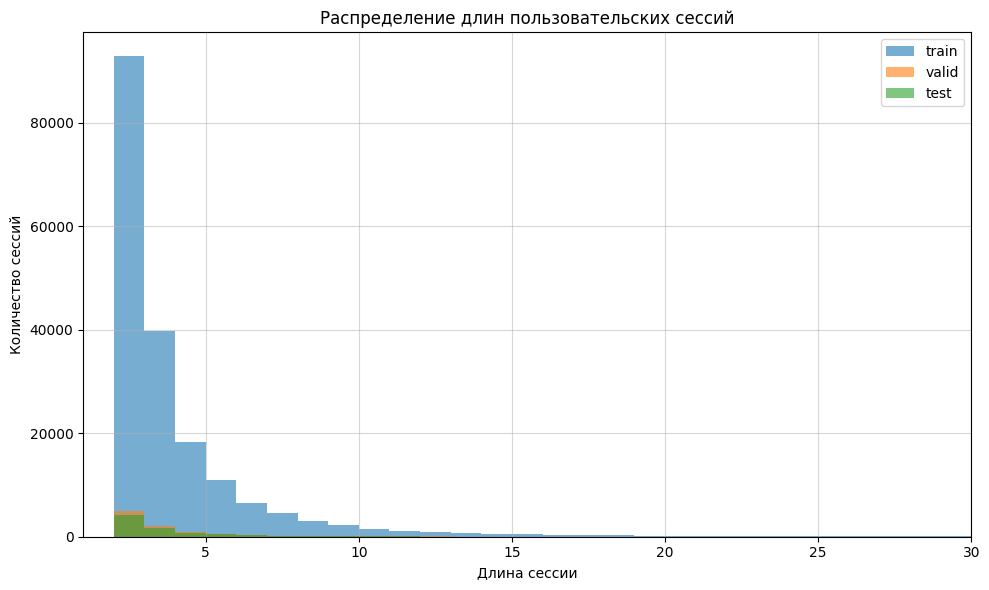

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Пути к файлам
train_path = "/kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_train_tr.tsv"
valid_path = "/kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_train_valid.tsv"
test_path  = "/kaggle/working/retailrocket_project/stage_01_retailrocket_preprocessing/retailrocket_processed_view_test.tsv"

# Загрузка
train_df = pd.read_csv(train_path, sep="\t")
valid_df = pd.read_csv(valid_path, sep="\t")
test_df  = pd.read_csv(test_path, sep="\t")

# Длины сессий
train_lens = train_df.groupby("SessionId").size()
valid_lens = valid_df.groupby("SessionId").size()
test_lens  = test_df.groupby("SessionId").size()

# Ограничиваем длину сессии до 50
train_lens_clip = train_lens[train_lens <= 50]
valid_lens_clip = valid_lens[valid_lens <= 50]
test_lens_clip  = test_lens[test_lens <= 50]

# График
plt.figure(figsize=(10, 6))

bins = range(1, 40)

plt.hist(train_lens_clip, bins=bins, alpha=0.6, label="train")
plt.hist(valid_lens_clip, bins=bins, alpha=0.6, label="valid")
plt.hist(test_lens_clip,  bins=bins, alpha=0.6, label="test")

plt.title("Распределение длин пользовательских сессий")
plt.xlabel("Длина сессии")
plt.ylabel("Количество сессий")
plt.xlim(1, 30)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import pickle
import pandas as pd

OUTPUT_DIR = "/kaggle/working/retailrocket_project/stage_03_session_model_after_anomaly_apply_all"

# === 1. Загружаем mapping ===
mapping_path = os.path.join(OUTPUT_DIR, "item_mapping.csv")
mapping_df = pd.read_csv(mapping_path)

# === 2. Восстанавливаем словари ===
item2idx = dict(zip(mapping_df["item_id"].astype(str), mapping_df["item_idx"].astype(int)))
idx2item = dict(zip(mapping_df["item_idx"].astype(int), mapping_df["item_id"].astype(str)))

# === 3. Сохраняем .pkl ===
with open(os.path.join(OUTPUT_DIR, "item2idx.pkl"), "wb") as f:
    pickle.dump(item2idx, f)

with open(os.path.join(OUTPUT_DIR, "idx2item.pkl"), "wb") as f:
    pickle.dump(idx2item, f)

print("✔ item2idx.pkl и idx2item.pkl сохранены")

# === 4. META ===
best_epochs_path = os.path.join(OUTPUT_DIR, "best_epochs_by_k.csv")
best_df = pd.read_csv(best_epochs_path)

row20 = best_df[best_df["k"] == 20].iloc[0]

meta = {
    "num_items": int(mapping_df["item_idx"].max() + 1),
    "main_k": 20,
    "best_epoch": int(row20["best_epoch_by_recall"]),
    "best_valid_recall@20": float(row20["best_valid_recall"]),
    "best_valid_mrr@20": float(row20["best_valid_mrr"]),
}

with open(os.path.join(OUTPUT_DIR, "meta.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print("✔ meta.json сохранён")
print(meta)